# 2. Churn: exploratory data analysis (IBM Telco)

**Business:** a telecom company with 7,043 customers in California. **26.5%** of them left ("churned") in the last quarter.

**Question for this notebook:** *who* churns? Which customer and contract characteristics go with high churn, before any model is built?

EDA comes first because it (1) catches data problems, (2) builds intuition to sanity-check the model later, and (3) often already answers the business question in a way managers understand.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import BLUE, ORANGE
from src.plots import churn_rate_bars, save, setup_style
from src.telco_data import FEATURES, LEAKAGE_COLUMNS, load_clean, load_raw

setup_style()

## Data quality and leakage check

The raw file has 33 columns. Some must **never** be used as model inputs because they contain the answer:

In [2]:
raw = load_raw()
print(raw.shape)
raw[["Churn Label", "Churn Score", "Churn Reason", "CLTV"]].head()

(7043, 33)


,Churn Label,Churn Score,Churn Reason,CLTV
0,Yes,86,Competitor made better offer,3239
1,Yes,67,Moved,2701
2,Yes,86,Moved,5372
3,Yes,84,Moved,5003
4,Yes,89,Competitor had better devices,5340


In [3]:
# Churn Reason is only filled in for customers who already left: a perfect giveaway.
raw.groupby("Churn Label")["Churn Reason"].apply(lambda s: s.notna().mean()).rename("share with a reason")

Churn Label
No     0.0
Yes    1.0
Name: share with a reason, dtype: float64

In [4]:
# Churn Score is IBM's own model output; it separates churners almost perfectly because it was built with the outcome.
raw.groupby("Churn Label")["Churn Score"].describe()[["mean", "min", "max"]]

,mean,min,max
Churn Label,,,
No,50.098183,5.0,80.0
Yes,82.510433,65.0,100.0


**Leakage:** `Churn Reason` exists only for churners, and `Churn Score` is another model's prediction. A model given these would look brilliant in testing but couldn't be used on *current* customers, who don't have a churn reason yet. `CLTV` (lifetime value) is also IBM-derived, so it's kept only to value customers, never as an input.

`src/telco_data.clean()` drops these, plus constant columns (country, state) and identifiers (ID, city, zip, coordinates). It also fixes 11 blank `Total Charges` for brand-new customers (tenure 0 → total 0).

In [5]:
df = load_clean()
print(df.shape, "| features used:", len(FEATURES))
overall = df["churn"].mean()
print(f"Overall churn rate: {overall:.1%}")
df.head()

(7043, 22) | features used: 19
Overall churn rate: 26.5%


,customer_id,cltv,tenure_months,monthly_charges,total_charges,gender,senior_citizen,partner,dependents,phone_service,...,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,churn
0,3668-QPYBK,3239,2,53.85,108.15,Male,No,No,No,Yes,...,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,1
1,9237-HQITU,2701,2,70.70,151.65,Female,No,No,Yes,Yes,...,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,1
2,9305-CDSKC,5372,8,99.65,820.50,Female,No,No,Yes,Yes,...,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,1
3,7892-POOKP,5003,28,104.80,3046.05,Female,No,Yes,Yes,Yes,...,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,1
4,0280-XJGEX,5340,49,103.70,5036.30,Male,No,No,Yes,Yes,...,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),1


## Contract and billing

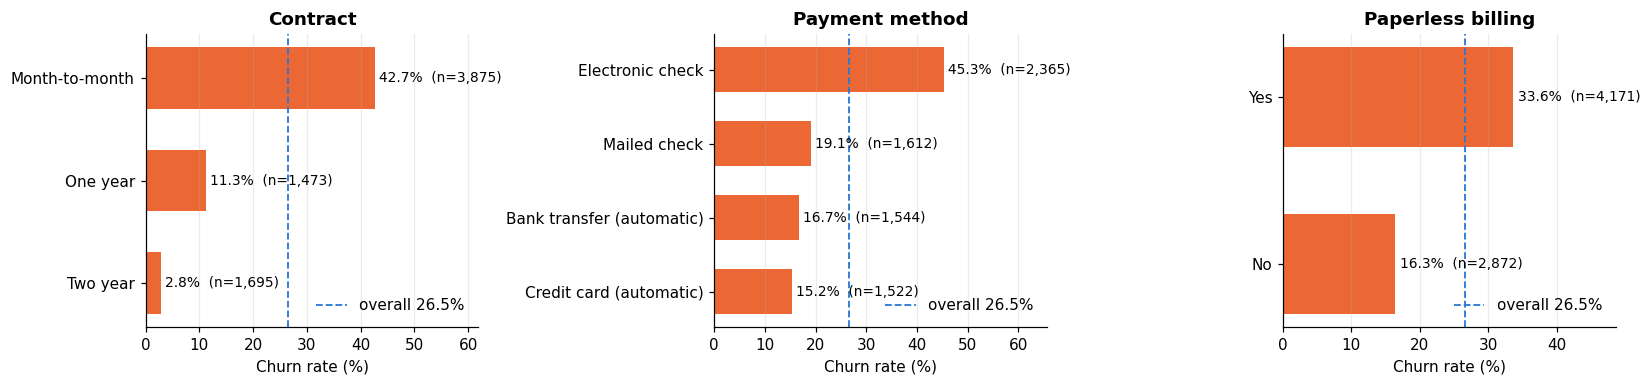

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["contract", "payment_method", "paperless_billing"]):
    churn_rate_bars(df, col, ax=ax, overall=overall)
fig.tight_layout()
save(fig, "eda_contract_billing")

- **Contract is the strongest signal.** Month-to-month customers churn at **42.7%**, vs 11.3% on one-year and **2.8%** on two-year contracts. A contract is both a commitment and a sign of satisfaction.
- **Electronic check** payers churn at **45.3%**, vs about 15–17% on automatic bank or card payments. Automatic payment removes a monthly "should I keep paying?" moment.

## Services

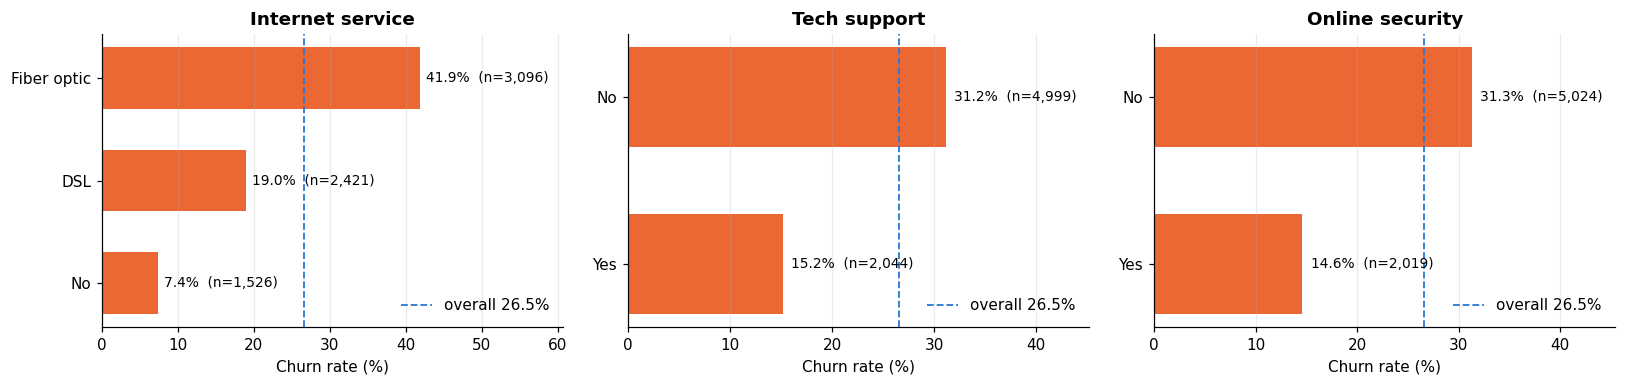

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["internet_service", "tech_support", "online_security"]):
    churn_rate_bars(df, col, ax=ax, overall=overall)
fig.tight_layout()
save(fig, "eda_services")

- **Fiber optic** customers churn at **41.9%**, more than twice the DSL rate (19.0%), even though fiber is the premium product. That suggests a price or quality problem worth investigating.
- **Tech support** and **online security** add-ons halve churn (about 15% vs 31%). These customers are more invested, and they get help when something breaks.

## Customer profile

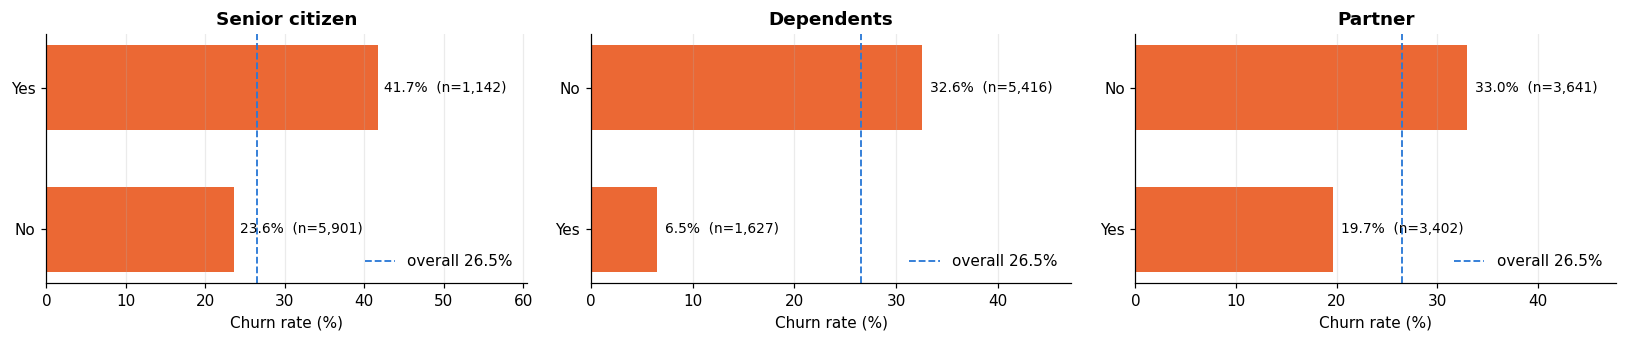

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, col in zip(axes, ["senior_citizen", "dependents", "partner"]):
    churn_rate_bars(df, col, ax=ax, overall=overall)
fig.tight_layout()
save(fig, "eda_profile")

## Tenure and charges

tenure_months
0-6      52.9
7-12     35.9
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn, dtype: float64

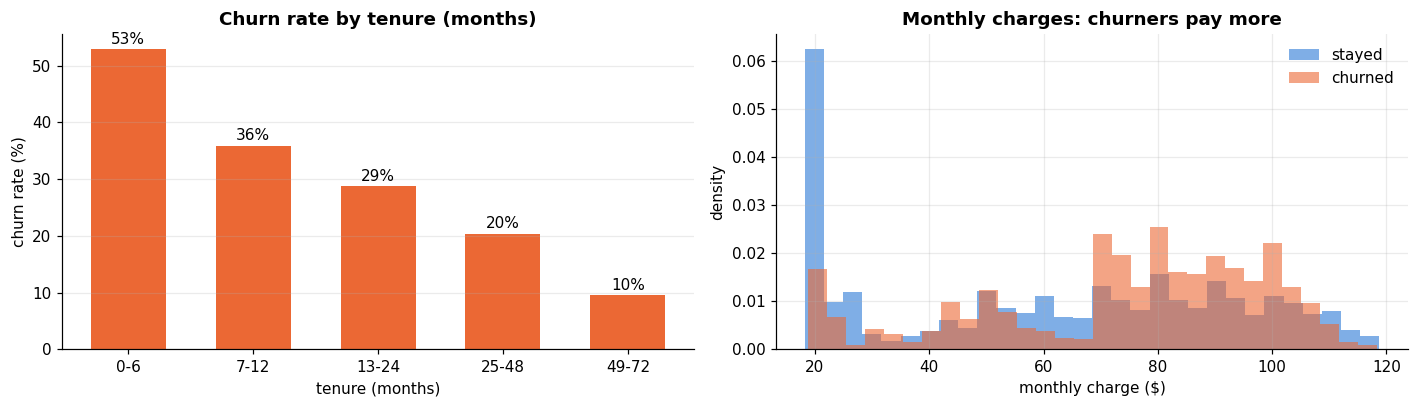

In [9]:
buckets = pd.cut(df["tenure_months"], [-1, 6, 12, 24, 48, 72],
                 labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
by_tenure = df.groupby(buckets, observed=True)["churn"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.bar(by_tenure.index.astype(str), by_tenure.values, color=ORANGE, width=0.6)
for i, v in enumerate(by_tenure.values):
    ax1.text(i, v + 1, f"{v:.0f}%", ha="center")
ax1.set(title="Churn rate by tenure (months)", xlabel="tenure (months)", ylabel="churn rate (%)")
ax1.grid(axis="x", visible=False)

for label, color, name in [(0, BLUE, "stayed"), (1, ORANGE, "churned")]:
    ax2.hist(df.loc[df["churn"] == label, "monthly_charges"], bins=30, alpha=0.6, color=color, label=name, density=True)
ax2.set(title="Monthly charges: churners pay more", xlabel="monthly charge ($)", ylabel="density")
ax2.legend(frameon=False)
fig.tight_layout()
save(fig, "eda_tenure_charges")
by_tenure.round(1)

- **The first 6 months are the danger zone:** over half of new customers in that window churn, falling to under 10% after 4 years. Onboarding matters most.
- **Churners pay more per month** (many are on fiber, month-to-month). High bills without a contract are a risky combination.

## Combining the two biggest drivers

In [10]:
combo = (df.groupby(["contract", "internet_service"])["churn"]
         .agg(churn_rate="mean", customers="size")
         .assign(churn_rate=lambda t: (t["churn_rate"] * 100).round(1))
         .sort_values("churn_rate", ascending=False))
combo

churn_rate  customers
contract       internet_service                       
Month-to-month Fiber optic             54.6       2128
               DSL                     32.2       1223
One year       Fiber optic             19.3        539
Month-to-month No                      18.9        524
One year       DSL                      9.3        570
Two year       Fiber optic              7.2        429
One year       No                       2.5        364
Two year       DSL                      1.9        628
               No                       0.8        638

**Month-to-month + fiber optic** is the highest-risk group in the data. It's a large group with over half of its customers churning, so it should be the first target for retention offers.

## Summary of EDA
| Driver | Higher churn | Lower churn |
|---|---|---|
| Contract | month-to-month (43%) | two-year (3%) |
| Payment | electronic check (45%) | automatic card/bank (15–17%) |
| Internet | fiber optic (42%) | no internet (7%) |
| Support add-ons | none (31%) | tech support (15%) |
| Tenure | first 6 months (>50%) | 4+ years (<10%) |

These are *associations*. Notebook 3 builds models that weigh them together, then checks which ones still matter once the others are accounted for.